# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:

# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (1920 * 1080 * 3 * 30 * 24 * 60 * 60 * 400) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps
fleet_tb_small = (640 * 360 * 3 * 10 * 24 * 60 * 60 * 400) / (1024 ** 4)

# Percentage of pixels remaining
pct_pixels_remaining = ((640 * 360) / (1920 * 1080)) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_Spatial evidence: Fine details such as a person's face, clothing and small objects may become difficult or impossible to identify because downsampling removes pixels.

Temporal evidence: Fast movements and short-duration events may be missed because reducing the frame rate from 30 fps to 10 fps removes two-thirds of the temporal samples.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

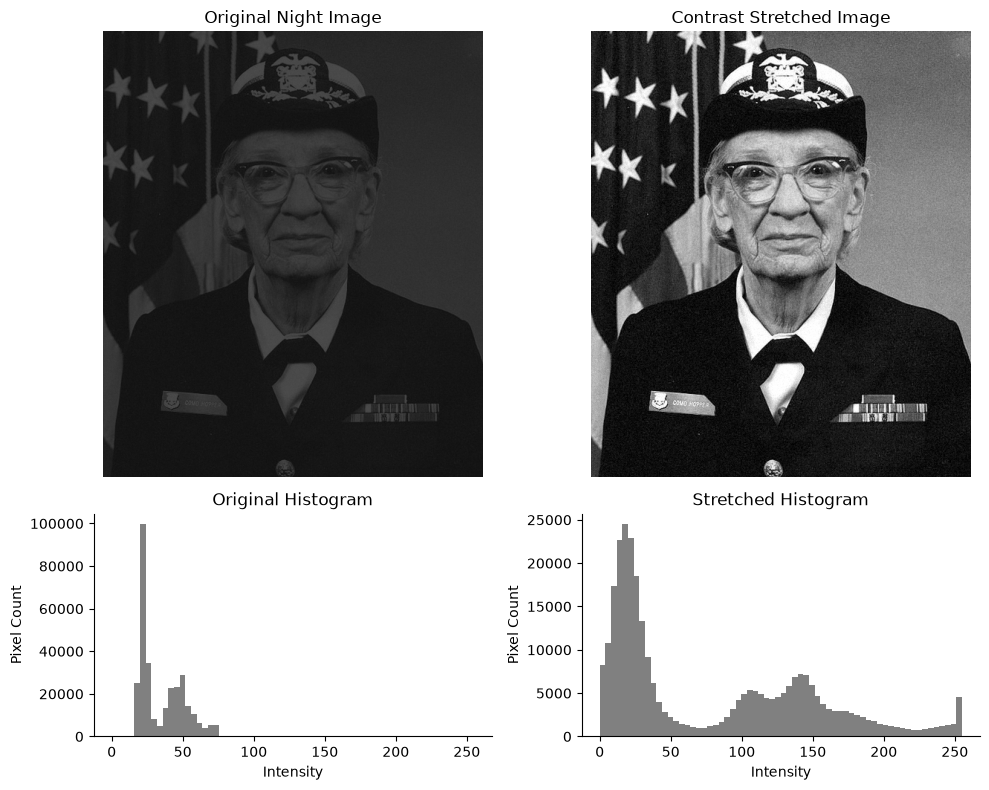

Contrast before: 0.609 -> after: 1.000


In [3]:

def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lmin = np.percentile(night_still, 1)
lmax = np.percentile(night_still, 99)

c_before = michelson(lmax, lmin)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip(
    (night_still - lmin) * 255 / (lmax - lmin),
    0, 255
)

c_after = michelson(
    np.percentile(stretched, 99),
    np.percentile(stretched, 1)
)

# TODO 1 & 4: images and histograms
fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# Original image
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

# Original histogram
axes[1, 0].hist(
    night_still.ravel(),
    bins=64,
    range=(0, 255),
    color="gray"
)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Intensity")
axes[1, 0].set_ylabel("Pixel Count")

# Stretched image
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Stretched Image")
axes[0, 1].axis("off")

# Stretched histogram
axes[1, 1].hist(
    stretched.ravel(),
    bins=64,
    range=(0, 255),
    color="gray"
)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlabel("Intensity")
axes[1, 1].set_ylabel("Pixel Count")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")


**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_The original night image has a left-concentrated and narrow histogram, indicating low brightness and low contrast. After contrast stretching, the intensity values are distributed across a wider range, making the image more readable.

Contrast stretching does not add new information because it only remaps existing pixel intensities. It improves the visibility of existing details. A histogram alone cannot identify objects or their positions because it removes spatial information. Two completely different images can have the same histogram.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).


Standing time ranges:
68.87 s - 70.53 s
70.60 s - 70.83 s
70.90 s - 71.13 s
71.20 s - 71.63 s
71.70 s - 72.03 s
72.10 s - 72.13 s
72.23 s - 72.73 s
72.80 s - 73.23 s
73.30 s - 73.73 s
73.80 s - 73.90 s
73.97 s - 74.03 s
74.10 s - 74.23 s
74.30 s - 74.67 s
74.73 s - 75.37 s
75.43 s - 75.47 s
75.53 s - 75.57 s
75.63 s - 75.67 s
75.80 s - 75.90 s
75.97 s - 76.53 s
76.63 s - 76.93 s
77.00 s - 78.10 s

Running time ranges:
78.60 s - 86.00 s

Audio event: 2250
Lighting event: 3000


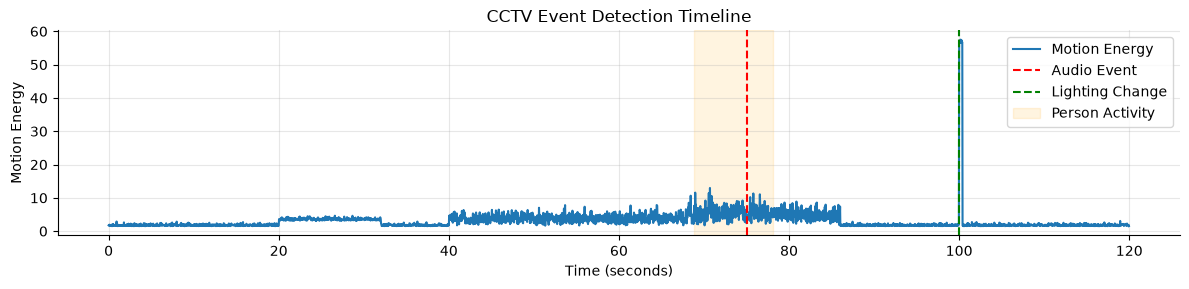

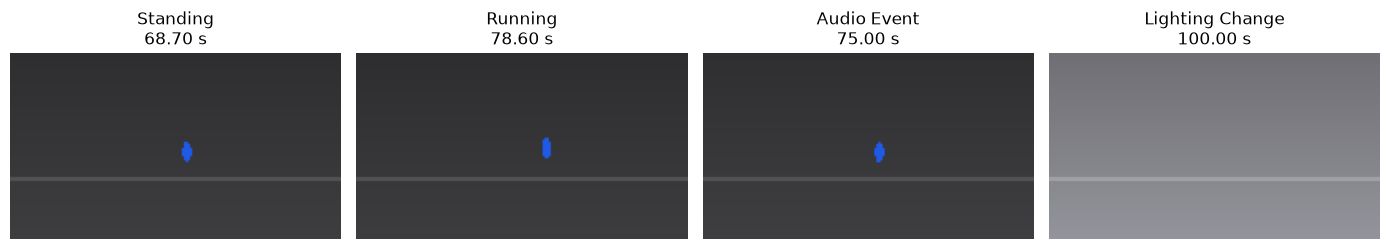

In [4]:

# TODO 1: person speed (px/s)
speed = np.hypot(
    cctv.person_x.diff(FPS),
    cctv.person_y.diff(FPS)
)

# TODO 2: standing / running time ranges
def print_time_ranges(mask, label):
    indices = np.where(mask.fillna(False).to_numpy())[0]

    if len(indices) == 0:
        print(f"{label}: No intervals found")
        return

    groups = np.split(
        indices,
        np.where(np.diff(indices) > 1)[0] + 1
    )

    print(f"\n{label} time ranges:")

    for group in groups:
        if len(group) >= 2:
            start = cctv.time_s.iloc[group[0]]
            end = cctv.time_s.iloc[group[-1]]
            print(f"{start:.2f} s - {end:.2f} s")


standing = speed < 3
running = speed > 25

print_time_ranges(standing, "Standing")
print_time_ranges(running, "Running")

# TODO 3: event frame indices
audio_event_idx = np.where(
    cctv.audio_level_db.to_numpy() > -20
)[0][0]

lighting_event_idx = np.where(
    cctv.mean_brightness.diff().to_numpy() > 40
)[0][0]

print("\nAudio event:", audio_event_idx)
print("Lighting event:", lighting_event_idx)

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(
    cctv.time_s,
    cctv.motion_energy,
    label="Motion Energy"
)

ax.axvline(
    cctv.time_s.iloc[audio_event_idx],
    color="red",
    linestyle="--",
    label="Audio Event"
)

ax.axvline(
    cctv.time_s.iloc[lighting_event_idx],
    color="green",
    linestyle="--",
    label="Lighting Change"
)

ax.axvspan(68.86, 78.1, color="orange", alpha=0.12,
           label="Person Activity")

ax.set_title("CCTV Event Detection Timeline")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# TODO 5: one representative keyframe per event
keyframe_indices = {
    "Standing": np.where(standing.to_numpy())[0][0],
    "Running": np.where(running.to_numpy())[0][0],
    "Audio Event": audio_event_idx,
    "Lighting Change": lighting_event_idx
}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, (event, idx) in zip(axes, keyframe_indices.items()):
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{event}\n{cctv.time_s.iloc[idx]:.2f} s")
    ax.axis("off")

plt.tight_layout()
plt.show()


**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_Uniform keyframes taken every 20 seconds could miss short-duration events such as the loud sound at 75 seconds and the beginning of the person's running movement around 78.6 seconds. This is because uniform sampling selects frames at fixed intervals regardless of scene activity.

The approach used here is called **content-based keyframe selection**, which selects important frames based on actual changes and events in the video.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

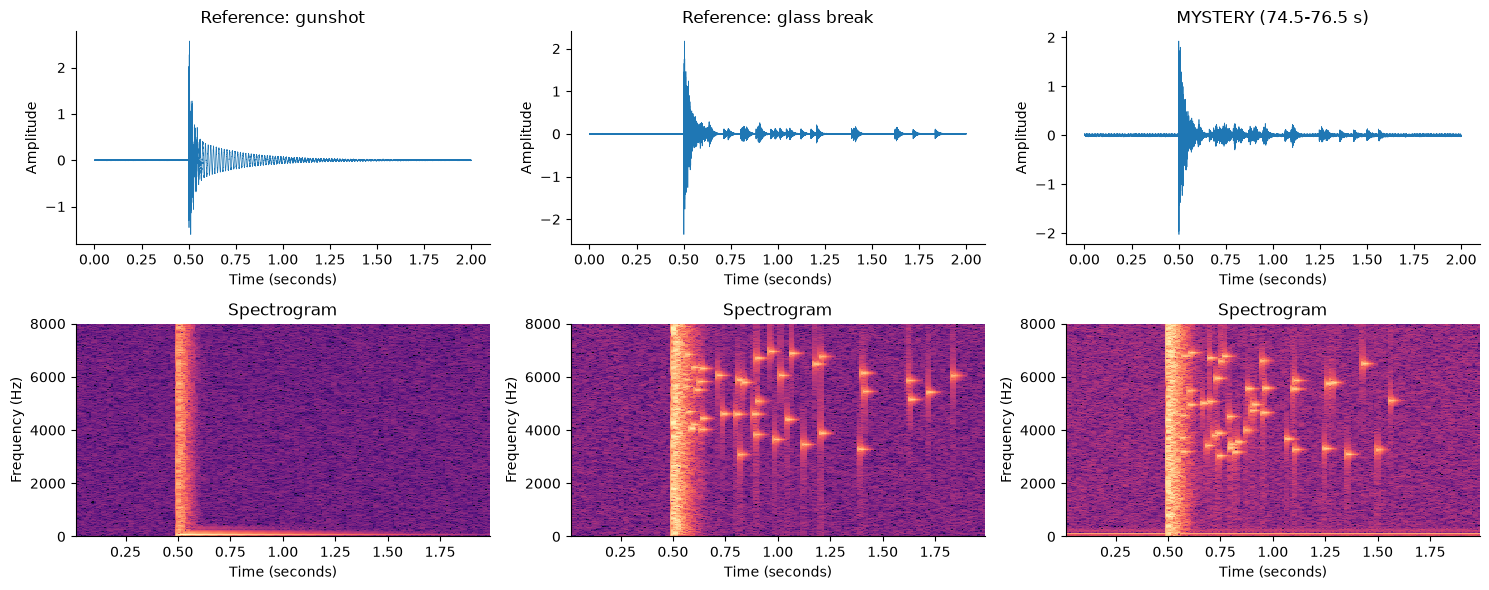

{'Reference: gunshot': np.float64(0.21536812880335363), 'Reference: glass break': np.float64(0.6377676959141664), 'MYSTERY (74.5-76.5 s)': np.float64(0.6562646133216412)}
VERDICT: The mystery sound is BREAKING GLASS.


In [5]:

mystery = x_audio[
    (t_audio >= 74.5) & (t_audio < 76.5)
]

clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: waveforms and spectrograms

for i, (name, clip) in enumerate(clips.items()):

    time = np.arange(len(clip)) / FS

    # Waveform
    axes[0, i].plot(time, clip, linewidth=0.5)
    axes[0, i].set_title(name)
    axes[0, i].set_xlabel("Time (seconds)")
    axes[0, i].set_ylabel("Amplitude")

    # Spectrogram
    f, tt, Sxx = signal.spectrogram(
        clip,
        fs=FS,
        nperseg=512,
        noverlap=384
    )

    pcm = axes[1, i].pcolormesh(
        tt,
        f,
        10 * np.log10(Sxx + 1e-12),
        shading="auto",
        cmap="magma"
    )

    axes[1, i].set_ylim(0, 8000)
    axes[1, i].set_xlabel("Time (seconds)")
    axes[1, i].set_ylabel("Frequency (Hz)")
    axes[1, i].set_title("Spectrogram")

plt.tight_layout()
plt.show()

# TODO 3: fraction of spectral energy above 3 kHz
hf_fraction = {}

for name, clip in clips.items():

    f, tt, Sxx = signal.spectrogram(
        clip,
        fs=FS,
        nperseg=512,
        noverlap=384
    )

    time_mask = (tt >= 0.2) & (tt <= 1.2)
    frequency_mask = f > 3000

    total_energy = Sxx[:, time_mask].sum()

    high_frequency_energy = Sxx[
        frequency_mask, :
    ][:, time_mask].sum()

    hf_fraction[name] = (
        high_frequency_energy / total_energy
    )

print(hf_fraction)

# TODO 4: verdict
gunshot_energy = hf_fraction["Reference: gunshot"]
glass_energy = hf_fraction["Reference: glass break"]
mystery_energy = hf_fraction["MYSTERY (74.5-76.5 s)"]

if abs(mystery_energy - glass_energy) < abs(mystery_energy - gunshot_energy):
    print("VERDICT: The mystery sound is BREAKING GLASS.")
else:
    print("VERDICT: The mystery sound is a GUNSHOT.")


**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_No, the waveforms alone cannot confidently distinguish a gunshot from breaking glass because both can produce a sudden, loud amplitude peak.

A spectrogram adds three dimensions: time, frequency and magnitude. The gunshot produces a short broadband impact with relatively little lingering high-frequency energy, whereas breaking glass produces scattered high-frequency specks between 3–7 kHz. The mystery recording resembles the glass reference, confirming that the sound is most likely breaking glass.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

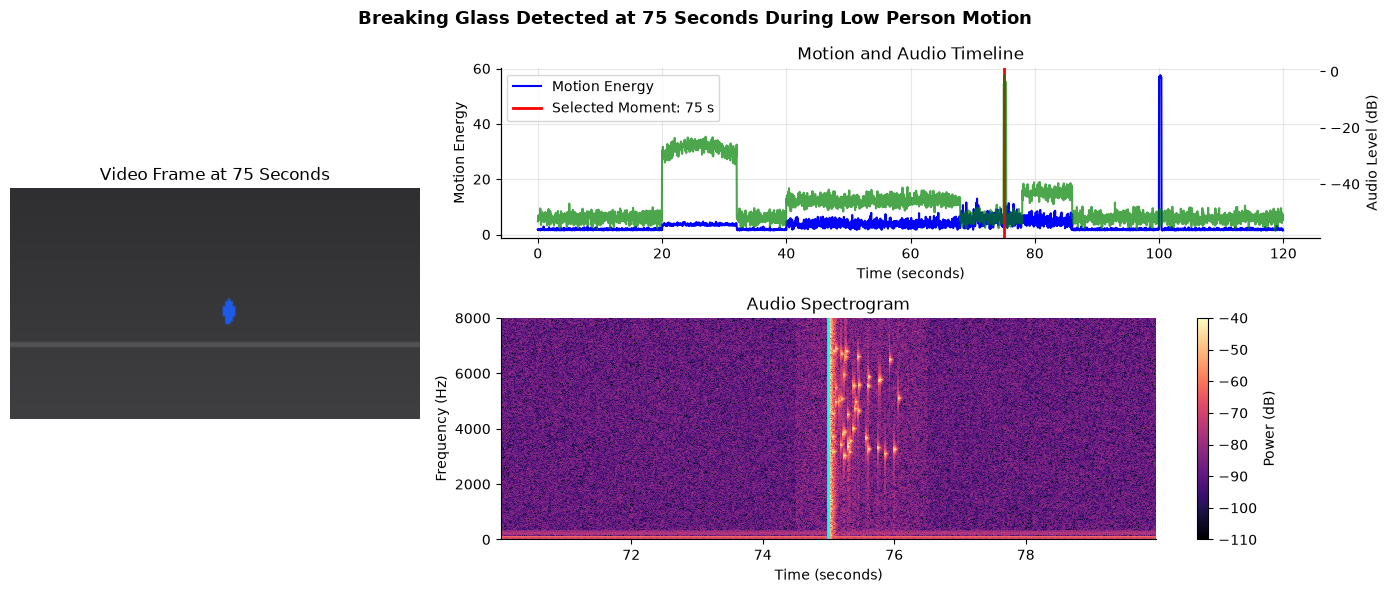

In [6]:

t_sel = 75.0

fig = plt.figure(figsize=(14, 6))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    height_ratios=[1, 1.3]
)

# TODO 1: video frame at 75 seconds
ax_frame = fig.add_subplot(gs[:, 0])

frame_idx = int(round(t_sel * FPS))

ax_frame.imshow(
    render_frame(cctv.iloc[frame_idx])
)

ax_frame.set_title("Video Frame at 75 Seconds")
ax_frame.axis("off")

# TODO 2: full motion + audio timeline
ax_timeline = fig.add_subplot(gs[0, 1])

ax_timeline.plot(
    cctv.time_s,
    cctv.motion_energy,
    color="blue",
    label="Motion Energy"
)

ax_audio = ax_timeline.twinx()

ax_audio.plot(
    cctv.time_s,
    cctv.audio_level_db,
    color="green",
    alpha=0.7,
    label="Audio Level"
)

ax_timeline.axvline(
    t_sel,
    color="red",
    linewidth=2,
    label="Selected Moment: 75 s"
)

ax_timeline.set_title("Motion and Audio Timeline")
ax_timeline.set_xlabel("Time (seconds)")
ax_timeline.set_ylabel("Motion Energy")
ax_audio.set_ylabel("Audio Level (dB)")

ax_timeline.legend(loc="upper left")
ax_timeline.grid(alpha=0.3)

# TODO 3: spectrogram of audio from 70-80 seconds
ax_spec = fig.add_subplot(gs[1, 1])

f, tt, Sxx = signal.spectrogram(
    x_audio,
    fs=FS,
    nperseg=512,
    noverlap=384
)

pcm = ax_spec.pcolormesh(
    tt + t_audio[0],
    f,
    10 * np.log10(Sxx + 1e-12),
    shading="auto",
    cmap="magma",
    vmin=-110,
    vmax=-40
)

ax_spec.axvline(
    t_sel,
    color="cyan",
    linewidth=2
)

ax_spec.set_ylim(0, 8000)
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio Spectrogram")

plt.colorbar(pcm, ax=ax_spec, label="Power (dB)")

# TODO 4: conclusion-style figure title
fig.suptitle(
    "Breaking Glass Detected at 75 Seconds During Low Person Motion",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_If the audio track were offset by +2 seconds, the sound at 75 seconds would appear at 77 seconds relative to the video. This could lead the security team to associate the sound with the wrong movement or event. The spectrogram and the timeline panel would reveal the synchronization error because their event markers would no longer align with the corresponding video moment.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_The CCTV footage from Parking Lot B shows a person standing relatively still around 68.9–78.1 seconds, followed by running activity from approximately 78.6–86 seconds. At 75 seconds, a loud sound is detected, and spectral analysis indicates that it is most likely breaking glass rather than a gunshot. I recommend presenting the synchronized multimodal view first because it combines the video frame, motion and audio spectrogram using a common time reference, helping identify events through structure, pattern, change and meaning. The storage calculation shows that 400 cameras recording uncompressed 1080p video at 30 fps would require approximately 5,866 TB per day, while 360p at 10 fps would require approximately 217.3 TB per day. A reduced-resolution storage policy may be considered, but the system must preserve sufficient spatial detail to identify people and objects and sufficient temporal detail to capture short-duration security events.